<a href="https://colab.research.google.com/github/Addreta/-fermi-hubbard-classical-benchmarks/blob/main/pauli_path_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install quspin openfermion qiskit qiskit-aer qiskit-nature qiskit-algorithms physics-tenpy

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.5/12.5 MB 87.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.5/38.5 MB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 55.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 57.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━

In [12]:
from openfermion.hamiltonians import fermi_hubbard
from openfermion.transforms import jordan_wigner
from qiskit.quantum_info import SparsePauliOp
import numpy as np

L = 4
t_hop = 1.0
U = 2.0
n_qubits = 2 * L  # 8 qubits for 4-site chain

# ── Hamiltonian construction ──────────────────────────────────────────────────

def openfermion_to_qiskit(qubit_operator, n_qubits):
    pauli_list = []
    for term, coeff in qubit_operator.terms.items():
        if abs(coeff) < 1e-10:
            continue
        assert abs(coeff.imag) < 1e-10, f"Unexpected imaginary coefficient: {coeff}"
        pauli_str = ['I'] * n_qubits
        for qubit_idx, pauli in term:
            pauli_str[qubit_idx] = pauli
        pauli_str = ''.join(reversed(pauli_str))  # OpenFermion → Qiskit little-endian
        pauli_list.append((pauli_str, coeff.real))
    return SparsePauliOp.from_list(pauli_list)

fh_op = fermi_hubbard(x_dimension=L, y_dimension=1,
                      tunneling=t_hop, coulomb=U, periodic=False)
jw_op  = jordan_wigner(fh_op)
H_qiskit = openfermion_to_qiskit(jw_op, n_qubits)

print(f"H_qiskit built: {len(H_qiskit.to_list())} Pauli terms")
print(f"n_qubits: {n_qubits}")

# ── Trotter gate builder ──────────────────────────────────────────────────────

def build_trotter_gates(H_qiskit, dt, n_qubits, order=2):
    """
    Returns a list of (pauli_tuple, angle) pairs representing Pauli rotations:
        exp(-i * angle/2 * P)
    where angle = 2 * coeff * dt  (Qiskit rotation gate convention).

    pauli_tuple: natural qubit order, index 0 = qubit 0 (leftmost site).
    """
    pauli_list = H_qiskit.to_list()

    hop_gates = []   # hopping terms: contain X or Y
    int_gates = []   # interaction/number terms: only Z and I

    for pauli_str, coeff in pauli_list:
        if abs(coeff) < 1e-10:
            continue
        if pauli_str == 'I' * n_qubits:
            continue

        # Reverse: Qiskit little-endian → natural order (qubit 0 at index 0)
        pauli_tuple = tuple(reversed(pauli_str))

        # Qiskit gate: R_P(θ) = exp(-i θ/2 P)
        # To implement exp(-i coeff dt P), need θ = 2 * coeff * dt
        angle = 2.0 * coeff * dt

        if 'X' in pauli_str or 'Y' in pauli_str:
            hop_gates.append((pauli_tuple, angle))
        else:
            int_gates.append((pauli_tuple, angle))

    # 2nd-order Suzuki-Trotter: H/2 · U · H/2
    if order == 2:
        gates = ([(p, a / 2) for p, a in hop_gates] +
                 int_gates +
                 [(p, a / 2) for p, a in hop_gates])
    elif order == 1:
        gates = hop_gates + int_gates
    else:
        raise ValueError(f"Unsupported Trotter order: {order}")

    return gates

# ── Test ──────────────────────────────────────────────────────────────────────

dt_pp = 0.1
gates_one_step = build_trotter_gates(H_qiskit, dt_pp, n_qubits, order=2)

print(f"\nNumber of gates per Trotter step: {len(gates_one_step)}")
print(f"First few gates (natural qubit order, qubit 0 at index 0):")
for g, a in gates_one_step[:5]:
    print(f"  {g}: angle={a:.6f}")

# ── Sanity check ──────────────────────────────────────────────────────────────

# Reconstruct H from gates and compare with H_qiskit matrix
from qiskit.quantum_info import SparsePauliOp, Operator
import numpy as np

def gates_to_hamiltonian(gates, n_qubits):
    """Reconstruct H from gate list: H = sum_k (angle_k / (2*dt)) * P_k"""
    # Not directly possible without dt, so just verify structure
    pauli_terms = []
    seen = {}
    for pauli_tuple, angle in gates:
        pauli_str = ''.join(reversed(pauli_tuple))  # back to Qiskit convention
        seen[pauli_str] = seen.get(pauli_str, 0) + angle
    return seen

term_map = gates_to_hamiltonian(gates_one_step, n_qubits)
print(f"\nUnique Pauli terms in gate list: {len(term_map)}")
print("Sample reconstructed coefficients (should be 2*coeff*dt for non-split terms):")
for k, v in list(term_map.items())[:4]:
    print(f"  {k}: summed_angle={v:.6f}")

H_qiskit built: 25 Pauli terms
n_qubits: 8

Number of gates per Trotter step: 36
First few gates (natural qubit order, qubit 0 at index 0):
  ('Y', 'Z', 'Y', 'I', 'I', 'I', 'I', 'I'): angle=-0.050000+0.000000j
  ('X', 'Z', 'X', 'I', 'I', 'I', 'I', 'I'): angle=-0.050000+0.000000j
  ('I', 'Y', 'Z', 'Y', 'I', 'I', 'I', 'I'): angle=-0.050000+0.000000j
  ('I', 'X', 'Z', 'X', 'I', 'I', 'I', 'I'): angle=-0.050000+0.000000j
  ('I', 'I', 'Y', 'Z', 'Y', 'I', 'I', 'I'): angle=-0.050000+0.000000j

Unique Pauli terms in gate list: 24
Sample reconstructed coefficients (should be 2*coeff*dt for non-split terms):
  IIIIIYZY: summed_angle=-0.100000+0.000000j
  IIIIIXZX: summed_angle=-0.100000+0.000000j
  IIIIYZYI: summed_angle=-0.100000+0.000000j
  IIIIXZXI: summed_angle=-0.100000+0.000000j


In [16]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# ── Pauli matrices ────────────────────────────────────────────────────────────
I_mat = np.eye(2, dtype=complex)
X_mat = np.array([[0,1],[1,0]], dtype=complex)
Y_mat = np.array([[0,-1j],[1j,0]], dtype=complex)
Z_mat = np.array([[1,0],[0,-1]], dtype=complex)
PAULIS = {'I': I_mat, 'X': X_mat, 'Y': Y_mat, 'Z': Z_mat}

# ── Pauli string algebra ──────────────────────────────────────────────────────
def pauli_string_commutes(P, Q):
    anticommuting_sites = 0
    for p, q in zip(P, Q):
        if p != 'I' and q != 'I' and p != q:
            anticommuting_sites += 1
    return anticommuting_sites % 2 == 0

def multiply_pauli_strings(P, Q):
    PAULI_PRODUCT = {
        ('I','I'):( 1,'I'), ('I','X'):( 1,'X'), ('I','Y'):( 1,'Y'), ('I','Z'):( 1,'Z'),
        ('X','I'):( 1,'X'), ('X','X'):( 1,'I'), ('X','Y'):(1j,'Z'), ('X','Z'):(-1j,'Y'),
        ('Y','I'):( 1,'Y'), ('Y','X'):(-1j,'Z'), ('Y','Y'):( 1,'I'), ('Y','Z'):(1j,'X'),
        ('Z','I'):( 1,'Z'), ('Z','X'):(1j,'Y'), ('Z','Y'):(-1j,'X'), ('Z','Z'):( 1,'I'),
    }
    phase = 1+0j
    result = []
    for p, q in zip(P, Q):
        ph, r = PAULI_PRODUCT[(p, q)]
        phase *= ph
        result.append(r)
    return phase, tuple(result)

# ── Core: backward gate application (Heisenberg picture) ─────────────────────
def apply_gate_backward(observable, gate_pauli, angle, n_qubits, epsilon):
    new_obs = {}
    gate_pauli = tuple(gate_pauli)
    for obs_pauli, coeff in observable.items():
        obs_pauli = tuple(obs_pauli)
        if pauli_string_commutes(gate_pauli, obs_pauli):
            new_obs[obs_pauli] = new_obs.get(obs_pauli, 0) + coeff
        else:
            c1 = coeff * np.cos(angle)
            if abs(c1) >= epsilon:
                new_obs[obs_pauli] = new_obs.get(obs_pauli, 0) + c1
            phase, new_pauli = multiply_pauli_strings(gate_pauli, obs_pauli)
            c2 = coeff * 1j * np.sin(angle) * phase
            if abs(c2) >= epsilon:
                new_obs[new_pauli] = new_obs.get(new_pauli, 0) + c2
    return new_obs

# ── Pauli path simulator ──────────────────────────────────────────────────────
def pauli_path_simulate(observable_init, gates_one_step, n_steps,
                         psi0, n_qubits, epsilon=1e-3):
    all_gates = gates_one_step * n_steps
    all_gates_reversed = list(reversed(all_gates))
    observable = dict(observable_init)
    for gate_pauli, angle in all_gates_reversed:
        observable = apply_gate_backward(observable, gate_pauli,
                                          angle, n_qubits, epsilon)
    result = 0.0
    for pauli_str, coeff in observable.items():
        mat = np.array([[1.0+0j]])
        for p in reversed(pauli_str):   # reversed: match Qiskit statevector ordering
            mat = np.kron(mat, PAULIS[p])
        result += coeff * (psi0.conj() @ mat @ psi0)
    return np.real(result)

# ── Néel observable ───────────────────────────────────────────────────────────
def build_neel_observable(L, n_qubits):
    obs = {}
    for i in range(L):
        up_qubit   = 2 * i
        down_qubit = 2 * i + 1
        sign = (-1)**i
        pauli = ['I'] * n_qubits
        pauli[up_qubit] = 'Z'
        obs[tuple(pauli)] = obs.get(tuple(pauli), 0) + sign * (-0.25) / L
        pauli = ['I'] * n_qubits
        pauli[down_qubit] = 'Z'
        obs[tuple(pauli)] = obs.get(tuple(pauli), 0) + sign * (0.25) / L
    return obs

# ── Initial state (Néel: sites 0↑, 1↓, 2↑, 3↓) ───────────────────────────────
qc_init = QuantumCircuit(n_qubits)
for q in [0, 4, 3, 7]:
    qc_init.x(q)
psi0_pp = Statevector(qc_init).data

# ── Verify ────────────────────────────────────────────────────────────────────
obs_init = build_neel_observable(L, n_qubits)
neel_check = pauli_path_simulate(obs_init, [], 0, psi0_pp, n_qubits, epsilon=0)
print(f"Initial Neel value (should be 0.5): {neel_check:.4f}")
print(f"Number of terms in observable: {len(obs_init)}")

Initial Neel value (should be 0.5): 0.5000
Number of terms in observable: 8


In [17]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from openfermion.hamiltonians import fermi_hubbard
from openfermion.transforms import jordan_wigner

# ── Pauli matrices ────────────────────────────────────────────────────────────
I_m = np.eye(2, dtype=complex)
X_m = np.array([[0,1],[1,0]], dtype=complex)
Y_m = np.array([[0,-1j],[1j,0]], dtype=complex)
Z_m = np.array([[1,0],[0,-1]], dtype=complex)
PAULIS = {'I': I_m, 'X': X_m, 'Y': Y_m, 'Z': Z_m}

# ── Parameters ────────────────────────────────────────────────────────────────
L = 4
t_hop = 1.0
U = 2.0
n_qubits = 2 * L

# ── Build Hamiltonian ─────────────────────────────────────────────────────────
def openfermion_to_qiskit(qubit_operator, n_qubits):
    pauli_list = []
    for term, coeff in qubit_operator.terms.items():
        if abs(coeff) < 1e-10:
            continue
        pauli_str = ['I'] * n_qubits
        for qubit_idx, pauli in term:
            pauli_str[qubit_idx] = pauli
        pauli_str = ''.join(reversed(pauli_str))   # OpenFermion → Qiskit little-endian
        pauli_list.append((pauli_str, coeff.real))
    return SparsePauliOp.from_list(pauli_list)

fh_op = fermi_hubbard(x_dimension=L, y_dimension=1,
                       tunneling=t_hop, coulomb=U, periodic=False)
H_qiskit = openfermion_to_qiskit(jordan_wigner(fh_op), n_qubits)

# ── Pauli string algebra ──────────────────────────────────────────────────────
def pauli_commutes(P, Q, n_qubits):
    anticommute_count = 0
    for i in range(n_qubits):
        p, q = P[i], Q[i]
        if p == 'I' or q == 'I':
            continue
        if p != q:
            anticommute_count += 1
    return (anticommute_count % 2) == 0

def pauli_commutator_coeff(P, Q, n_qubits):
    """Compute P*Q for anticommuting Pauli strings.
    Returns (2 * phase_of_PQ, result_string) so caller uses c_comm/2."""
    if pauli_commutes(P, Q, n_qubits):
        return 0, None
    coeff = 1.0 + 0j
    result = []
    pairs = {
        ('X','Y'): ( 1j,'Z'), ('Y','X'): (-1j,'Z'),
        ('Y','Z'): ( 1j,'X'), ('Z','Y'): (-1j,'X'),
        ('Z','X'): ( 1j,'Y'), ('X','Z'): (-1j,'Y'),
    }
    for i in range(n_qubits):
        p, q = P[i], Q[i]
        if p == 'I':
            result.append(q)
        elif q == 'I':
            result.append(p)
        elif p == q:
            result.append('I')
        else:
            c, r = pairs[(p, q)]
            coeff *= c
            result.append(r)
    return 2 * coeff, tuple(result)

# ── Apply gate backward (Heisenberg picture) ──────────────────────────────────
def apply_gate_backward(observable, gate_pauli, angle, n_qubits, epsilon):
    """
    Update observable under conjugation by exp(-i * angle * P):
        e^{+i*angle*P} Q e^{-i*angle*P}
            = cos(2*angle)*Q + i*sin(2*angle)*PQ   [if P,Q anticommute]
            = Q                                     [if P,Q commute]
    """
    new_observable = {}
    for pauli_str, coeff in observable.items():
        if pauli_commutes(gate_pauli, pauli_str, n_qubits):
            new_observable[pauli_str] = new_observable.get(pauli_str, 0) + coeff
        else:
            c_comm, R = pauli_commutator_coeff(gate_pauli, pauli_str, n_qubits)
            cos_term = np.cos(2 * angle) * coeff
            sin_term = 1j * np.sin(2 * angle) * (c_comm / 2) * coeff   # c_comm/2 = phase_PQ
            new_observable[pauli_str] = new_observable.get(pauli_str, 0) + cos_term
            if R is not None:
                new_observable[R] = new_observable.get(R, 0) + sin_term
    return {k: v for k, v in new_observable.items() if abs(v) > epsilon}

# ── Build Trotter gates ───────────────────────────────────────────────────────
def build_trotter_gates(H_qiskit, dt, n_qubits, order=2):
    """
    Stores angle = coeff * dt (= α in exp(-i*α*P)).
    apply_gate_backward uses cos(2α), sin(2α) — internally consistent.
    """
    pauli_list = H_qiskit.to_list()
    hop_gates = []
    int_gates = []
    for pauli_str, coeff in pauli_list:
        if abs(coeff) < 1e-10:
            continue
        if pauli_str == 'I' * n_qubits:
            continue
        pauli_tuple = tuple(reversed(pauli_str))   # Qiskit little-endian → natural order
        angle = coeff.real * dt                    # α = coeff * dt
        if 'X' in pauli_str or 'Y' in pauli_str:
            hop_gates.append((pauli_tuple, angle))
        else:
            int_gates.append((pauli_tuple, angle))
    if order == 2:
        # S₂(t) = exp(H_hop·t/2) exp(H_int·t) exp(H_hop·t/2)
        gates = ([(p, a / 2) for p, a in hop_gates] +
                 int_gates +
                 [(p, a / 2) for p, a in hop_gates])
    else:
        gates = hop_gates + int_gates
    return gates

# ── Pauli path simulation ─────────────────────────────────────────────────────
def pauli_path_simulate(observable_init, gates_one_step, n_steps,
                         psi0, n_qubits, epsilon=1e-3):
    all_gates = gates_one_step * n_steps
    all_gates_reversed = list(reversed(all_gates))   # apply last gate first
    observable = dict(observable_init)
    for gate_pauli, angle in all_gates_reversed:
        observable = apply_gate_backward(observable, gate_pauli,
                                          angle, n_qubits, epsilon)
    result = 0.0
    for pauli_str, coeff in observable.items():
        mat = np.array([[1.0+0j]])
        for p in reversed(pauli_str):    # ✅ FIX: natural order → Qiskit little-endian
            mat = np.kron(mat, PAULIS[p])
        result += coeff * (psi0.conj() @ mat @ psi0)
    return np.real(result)

# ── Néel observable ───────────────────────────────────────────────────────────
def build_neel_observable(L, n_qubits):
    """
    N = (1/L) Σ_i (-1)^i (n_{i↑} - n_{i↓}) / 2
    Using n = (1-Z)/2:  n_{i↑} - n_{i↓} = (Z_{i↓} - Z_{i↑}) / 2
    Max value = 0.5 for perfect Néel state.
    """
    obs = {}
    for i in range(L):
        up_qubit   = 2 * i
        down_qubit = 2 * i + 1
        sign = (-1)**i
        pauli = ['I'] * n_qubits
        pauli[up_qubit] = 'Z'
        obs[tuple(pauli)] = obs.get(tuple(pauli), 0) + sign * (-0.25) / L
        pauli = ['I'] * n_qubits
        pauli[down_qubit] = 'Z'
        obs[tuple(pauli)] = obs.get(tuple(pauli), 0) + sign * ( 0.25) / L
    return obs

# ── Initial state: Néel (sites 0↑, 1↓, 2↑, 3↓) ───────────────────────────────
qc_init = QuantumCircuit(n_qubits)
for q in [0, 4, 3, 7]:     # up: qubits 0,4 (sites 0,2); down: qubits 3,7 (sites 1,3)
    qc_init.x(q)
psi0_pp = Statevector(qc_init).data

# ── Gates ─────────────────────────────────────────────────────────────────────
dt_pp = 0.1
gates_one_step = build_trotter_gates(H_qiskit, dt_pp, n_qubits, order=2)

# ── Verify ────────────────────────────────────────────────────────────────────
obs_init = build_neel_observable(L, n_qubits)
neel_t0  = pauli_path_simulate(obs_init, [], 0, psi0_pp, n_qubits, epsilon=0)

print(f"Setup complete.")
print(f"Gates per step:  {len(gates_one_step)}")
print(f"Initial Néel (expect 0.5): {neel_t0:.6f}")

Setup complete.
Gates per step:  36
Initial Néel (expect 0.5): 0.500000


Hermiticity check passed!
Symmetry checks passed!
Particle conservation check passed!
Exact done.
ε=1e-01 done. Final m(t)=0.0000
ε=1e-02 done. Final m(t)=0.3223
ε=1e-03 done. Final m(t)=0.0185
All Pauli path done.


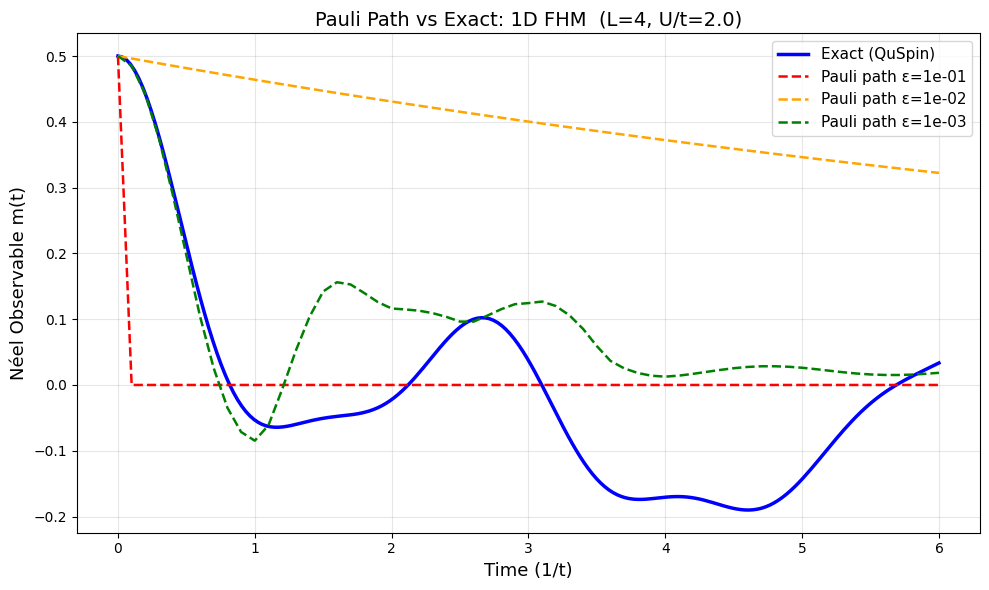

In [18]:
from quspin.operators import hamiltonian
from quspin.basis import spinful_fermion_basis_1d
from openfermion.hamiltonians import fermi_hubbard
from openfermion.transforms import jordan_wigner
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np
import matplotlib.pyplot as plt

# ── Parameters ────────────────────────────────────────────────────────────────
L      = 4
t_hop  = 1.0
U      = 2.0
n_qubits = 2 * L
dt_pp  = 0.1

# ── Pauli matrices ────────────────────────────────────────────────────────────
I_m = np.eye(2, dtype=complex)
X_m = np.array([[0,1],[1,0]], dtype=complex)
Y_m = np.array([[0,-1j],[1j,0]], dtype=complex)
Z_m = np.array([[1,0],[0,-1]], dtype=complex)
PAULIS = {'I': I_m, 'X': X_m, 'Y': Y_m, 'Z': Z_m}

# ── Build Qiskit Hamiltonian ──────────────────────────────────────────────────
def openfermion_to_qiskit(qubit_operator, n_qubits):
    pauli_list = []
    for term, coeff in qubit_operator.terms.items():
        if abs(coeff) < 1e-10:
            continue
        pauli_str = ['I'] * n_qubits
        for qubit_idx, pauli in term:
            pauli_str[qubit_idx] = pauli
        pauli_str = ''.join(reversed(pauli_str))
        pauli_list.append((pauli_str, coeff.real))
    return SparsePauliOp.from_list(pauli_list)

fh_op    = fermi_hubbard(x_dimension=L, y_dimension=1,
                          tunneling=t_hop, coulomb=U, periodic=False)
H_qiskit = openfermion_to_qiskit(jordan_wigner(fh_op), n_qubits)

# ── Pauli string algebra ──────────────────────────────────────────────────────
def pauli_commutes(P, Q, n_qubits):
    count = sum(1 for i in range(n_qubits)
                if P[i] != 'I' and Q[i] != 'I' and P[i] != Q[i])
    return count % 2 == 0

def pauli_commutator_coeff(P, Q, n_qubits):
    if pauli_commutes(P, Q, n_qubits):
        return 0, None
    pairs = {
        ('X','Y'):( 1j,'Z'), ('Y','X'):(-1j,'Z'),
        ('Y','Z'):( 1j,'X'), ('Z','Y'):(-1j,'X'),
        ('Z','X'):( 1j,'Y'), ('X','Z'):(-1j,'Y'),
    }
    coeff, result = 1.0+0j, []
    for p, q in zip(P, Q):
        if   p == 'I':          result.append(q)
        elif q == 'I':          result.append(p)
        elif p == q:            result.append('I')
        else:
            c, r = pairs[(p, q)]
            coeff *= c
            result.append(r)
    return 2 * coeff, tuple(result)

# ── Heisenberg backward gate application ──────────────────────────────────────
def apply_gate_backward(observable, gate_pauli, angle, n_qubits, epsilon):
    """
    e^{+i*angle*P} Q e^{-i*angle*P}:
        commutes    → Q  unchanged
        anticommutes → cos(2α)·Q  +  i·sin(2α)·PQ
    """
    new_obs = {}
    for pauli_str, coeff in observable.items():
        if pauli_commutes(gate_pauli, pauli_str, n_qubits):
            new_obs[pauli_str] = new_obs.get(pauli_str, 0) + coeff
        else:
            c_comm, R = pauli_commutator_coeff(gate_pauli, pauli_str, n_qubits)
            c1 = np.cos(2 * angle) * coeff
            c2 = 1j * np.sin(2 * angle) * (c_comm / 2) * coeff
            new_obs[pauli_str] = new_obs.get(pauli_str, 0) + c1
            if R is not None:
                new_obs[R] = new_obs.get(R, 0) + c2
    return {k: v for k, v in new_obs.items() if abs(v) > epsilon}

# ── Trotter gate builder ──────────────────────────────────────────────────────
def build_trotter_gates(H_qiskit, dt, n_qubits, order=2):
    hop_gates, int_gates = [], []
    for pauli_str, coeff in H_qiskit.to_list():
        if abs(coeff) < 1e-10 or pauli_str == 'I' * n_qubits:
            continue
        pt    = tuple(reversed(pauli_str))   # → natural order (qubit 0 at index 0)
        angle = coeff.real * dt              # α: gate = exp(-i·α·P)
        (hop_gates if ('X' in pauli_str or 'Y' in pauli_str) else int_gates
         ).append((pt, angle))
    if order == 2:
        return ([(p, a/2) for p, a in hop_gates] +
                int_gates +
                [(p, a/2) for p, a in hop_gates])
    return hop_gates + int_gates

# ── Pauli path simulator ──────────────────────────────────────────────────────
def pauli_path_simulate(observable_init, gates_one_step, n_steps,
                         psi0, n_qubits, epsilon=1e-3):
    observable = dict(observable_init)
    for gate_pauli, angle in reversed(gates_one_step * n_steps):
        observable = apply_gate_backward(observable, gate_pauli,
                                          angle, n_qubits, epsilon)
    result = 0.0
    for pauli_str, coeff in observable.items():
        mat = np.array([[1.0+0j]])
        for p in reversed(pauli_str):    # ✅ reversed: natural order → Qiskit LSB
            mat = np.kron(mat, PAULIS[p])
        result += coeff * (psi0.conj() @ mat @ psi0)
    return np.real(result)

# ── Néel observable ───────────────────────────────────────────────────────────
def build_neel_observable(L, n_qubits):
    # N = (1/L) Σ_i (-1)^i Sz_i,  Sz_i = (Z_{down_i} - Z_{up_i}) / 4
    obs = {}
    for i in range(L):
        sign = (-1)**i
        for qubit, c in [(2*i, -0.25/L), (2*i+1, +0.25/L)]:
            key = ['I'] * n_qubits
            key[qubit] = 'Z'
            key = tuple(key)
            obs[key] = obs.get(key, 0) + sign * c
    return obs

# ── Initial states ────────────────────────────────────────────────────────────
# Qiskit: sites 0↑, 1↓, 2↑, 3↓  →  qubits 0, 3, 4, 7
qc_init = QuantumCircuit(n_qubits)
for q in [0, 4, 3, 7]:
    qc_init.x(q)
psi0_pp = Statevector(qc_init).data

# QuSpin: same Néel state
basis    = spinful_fermion_basis_1d(L, Nf=(2, 2))
hop      = [[-t_hop, i, i+1] for i in range(L-1)] + \
           [[-t_hop, i+1, i] for i in range(L-1)]
static   = [["+-|", hop], ["|+-", hop], ["n|n", [[U, i, i] for i in range(L)]]]
H_qs     = hamiltonian(static, [], basis=basis, dtype=np.complex128)
neel_idx = basis.index("1010", "0101")          # sites 0,2 up; sites 1,3 down
psi0_qs  = np.zeros(basis.Ns, dtype=np.complex128)
psi0_qs[neel_idx] = 1.0

# ── QuSpin exact time evolution ───────────────────────────────────────────────
def build_Sz(site, basis):
    return hamiltonian([["n|", [[0.5, site]]], ["|n", [[-0.5, site]]]],
                       [], basis=basis, dtype=np.complex128,
                       check_symm=False, check_herm=False, check_pcon=False)

Sz_ops      = [build_Sz(i, basis) for i in range(L)]
times_exact = np.linspace(0, 6.0, 200)
psi_t       = H_qs.evolve(psi0_qs, 0, times_exact)   # shape (Ns, Nt)
neel_exact  = sum(
    ((-1)**i) * np.real(np.einsum('it,ij,jt->t',
        psi_t.conj(), Sz_ops[i].toarray(), psi_t))
    for i in range(L)
) / L
print("Exact done.")

# ── Pauli path time evolution ─────────────────────────────────────────────────
gates_one_step  = build_trotter_gates(H_qiskit, dt_pp, n_qubits, order=2)
t_max           = 6.0
n_steps_total   = int(t_max / dt_pp)             # 60
times_pp        = np.linspace(0, t_max, n_steps_total + 1)

epsilon_values  = [1e-1, 1e-2, 1e-3]
colors_pp       = ['red', 'orange', 'green']
neel_pp_results = {}

obs_init = build_neel_observable(L, n_qubits)
for epsilon in epsilon_values:
    neel_pp = [pauli_path_simulate(obs_init, [], 0, psi0_pp, n_qubits, 0)]  # t=0 exact
    for step in range(1, n_steps_total + 1):
        m = pauli_path_simulate(obs_init, gates_one_step,
                                 step, psi0_pp, n_qubits, epsilon)
        neel_pp.append(m)
    neel_pp_results[epsilon] = neel_pp
    print(f"ε={epsilon:.0e} done. Final m(t)={neel_pp[-1]:.4f}")

print("All Pauli path done.")

# ── Plot ──────────────────────────────────────────────────────────────────────
plt.figure(figsize=(10, 6))
plt.plot(times_exact, neel_exact, 'b-', linewidth=2.5, label='Exact (QuSpin)')
for epsilon, color in zip(epsilon_values, colors_pp):
    plt.plot(times_pp, neel_pp_results[epsilon], color=color,
             linestyle='--', linewidth=1.8, label=f'Pauli path ε={epsilon:.0e}')
plt.xlabel('Time (1/t)', fontsize=13)
plt.ylabel('Néel Observable m(t)', fontsize=13)
plt.title(f'Pauli Path vs Exact: 1D FHM  (L={L}, U/t={U/t_hop:.1f})', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('pauli_path_neel.png', dpi=150)
plt.show()


Running ε=1e-03...
  step 60/60, terms=120
ε=1e-03 done. Final m(t)=0.0185

Running ε=1e-04...
  step 60/60, terms=10253
ε=1e-04 done. Final m(t)=-0.0073

Running ε=1e-05...
  step 60/60, terms=9412
ε=1e-05 done. Final m(t)=0.0326


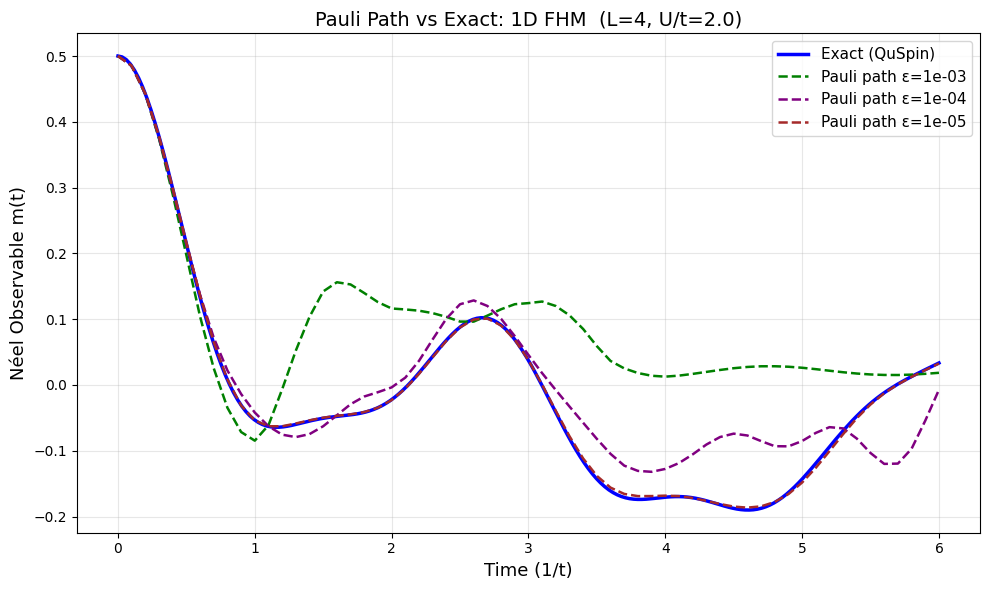

In [22]:
def pauli_path_simulate_incremental(observable_init, gates_one_step, n_steps_total,
                                     psi0, n_qubits, epsilon=1e-3):


    all_gates = gates_one_step * n_steps_total
    all_gates_reversed = list(reversed(all_gates))
    gates_per_step = len(gates_one_step)

    results = []
    observable = dict(observable_init)

    # Compute t=0
    val0 = _expectation(observable_init, psi0, n_qubits)
    results.append(val0)

    observable = dict(observable_init)
    for step in range(1, n_steps_total + 1):
        step_gates_reversed = list(reversed(gates_one_step))
        for gate_pauli, angle in step_gates_reversed:
            observable = apply_gate_backward(observable, gate_pauli,
                                              angle, n_qubits, epsilon)
        val = _expectation(observable, psi0, n_qubits)
        results.append(val)
        print(f"  step {step}/{n_steps_total}, terms={len(observable)}", end='\r')

    return results


def _expectation(observable, psi0, n_qubits):
    result = 0.0
    for pauli_str, coeff in observable.items():
        mat = np.array([[1.0+0j]])
        for p in reversed(pauli_str):
            mat = np.kron(mat, PAULIS[p])
        result += coeff * (psi0.conj() @ mat @ psi0)
    return np.real(result)
    epsilon_values_fine = [1e-3, 1e-4, 1e-5]
colors_fine         = ['green', 'purple', 'brown']
neel_pp_fine        = {}

for epsilon in epsilon_values_fine:
    print(f"\nRunning ε={epsilon:.0e}...")
    neel_pp = pauli_path_simulate_incremental(
        build_neel_observable(L, n_qubits),
        gates_one_step, n_steps_total,
        psi0_pp, n_qubits, epsilon
    )
    neel_pp_fine[epsilon] = neel_pp
    print(f"\nε={epsilon:.0e} done. Final m(t)={neel_pp[-1]:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(times_exact, neel_exact, 'b-', linewidth=2.5, label='Exact (QuSpin)')
for epsilon, color in zip(epsilon_values_fine, colors_fine):
    plt.plot(times_pp, neel_pp_fine[epsilon], color=color,
             linestyle='--', linewidth=1.8,
             label=f'Pauli path ε={epsilon:.0e}')
plt.xlabel('Time (1/t)', fontsize=13)
plt.ylabel('Néel Observable m(t)', fontsize=13)
plt.title(f'Pauli Path vs Exact: 1D FHM  (L={L}, U/t={U/t_hop:.1f})', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('pauli_path_fine.png', dpi=150)
plt.show()

ε=1e-01: m=0.0000, error=0.037179
ε=1e-02: m=0.4003, error=0.363166
ε=1e-03: m=0.1244, error=0.087242
ε=1e-04: m=0.0456, error=0.008440
ε=1e-05: m=0.0377, error=0.000500


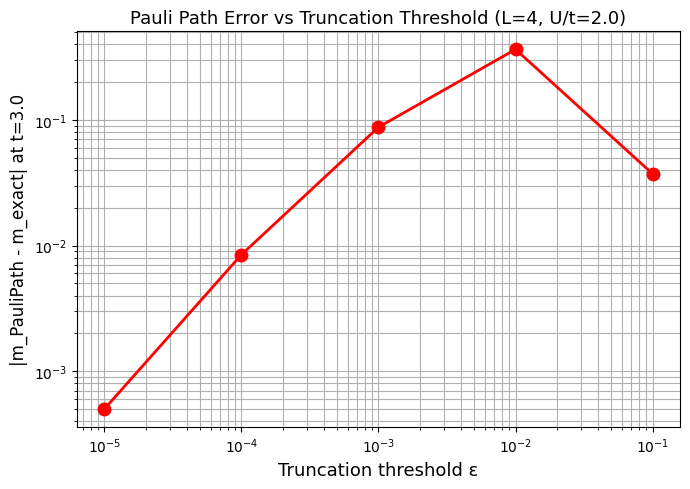

In [23]:
# Error vs epsilon at fixed time (analogous to Trotter error vs dt, TDVP error vs chi)
t_fixed = 3.0
step_fixed = int(t_fixed / dt_pp)
neel_exact_t = np.interp(t_fixed, times_exact, neel_exact)

epsilon_test = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
errors_pp = []

for epsilon in epsilon_test:
    obs = build_neel_observable(L, n_qubits)
    m = pauli_path_simulate(obs, gates_one_step,
                             step_fixed, psi0_pp, n_qubits, epsilon)
    err = abs(m - neel_exact_t)
    errors_pp.append(err)
    print(f"ε={epsilon:.0e}: m={m:.4f}, error={err:.6f}")

plt.figure(figsize=(7, 5))
plt.loglog(epsilon_test, errors_pp, 'ro-', linewidth=2, markersize=9)
plt.xlabel('Truncation threshold ε', fontsize=13)
plt.ylabel(f'|m_PauliPath - m_exact| at t={t_fixed}', fontsize=12)
plt.title(f'Pauli Path Error vs Truncation Threshold (L={L}, U/t={U})', fontsize=13)
plt.grid(True, which='both')
plt.tight_layout()
plt.savefig('pauli_path_error_vs_epsilon.png', dpi=150)
plt.show()


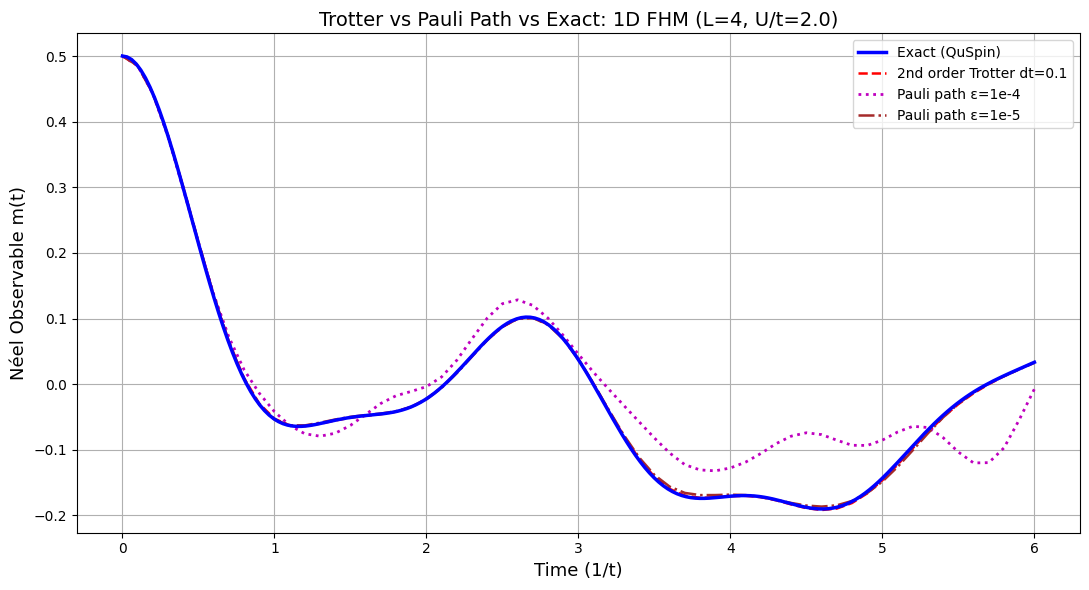

In [24]:
# Final comparison plot
from scipy.linalg import expm
from qiskit.quantum_info import SparsePauliOp

# Recompute Trotter 2nd order dt=0.1
pauli_list_q = H_qiskit.to_list()
H_hop_matrix = SparsePauliOp.from_list([(p,c) for p,c in pauli_list_q
                                         if 'X' in p or 'Y' in p]).to_matrix()
H_int_matrix = SparsePauliOp.from_list([(p,c) for p,c in pauli_list_q
                                         if 'X' not in p and 'Y' not in p]).to_matrix()
H_matrix = H_qiskit.to_matrix()

def build_Sz_matrix(site, n_qubits):
    up_qubit   = 2 * site
    down_qubit = 2 * site + 1
    up_str   = 'I'*(n_qubits-up_qubit-1) + 'Z' + 'I'*up_qubit
    down_str = 'I'*(n_qubits-down_qubit-1) + 'Z' + 'I'*down_qubit
    return SparsePauliOp.from_list([(up_str,-0.25),(down_str,0.25)]).to_matrix()

Sz_matrices = [build_Sz_matrix(i, n_qubits) for i in range(L)]
def measure_neel_q(psi):
    return sum(((-1)**i)*np.real(psi.conj() @ Sz_matrices[i] @ psi)
               for i in range(L)) / L

dt_tr = 0.1
U_hop_h = expm(-1j*(dt_tr/2)*H_hop_matrix)
U_int_f = expm(-1j*dt_tr*H_int_matrix)
psi = psi0_pp.copy()
neel_2nd = [measure_neel_q(psi)]
times_tr = [0.0]
for step in range(int(6.0/dt_tr)):
    psi = U_hop_h @ (U_int_f @ (U_hop_h @ psi))
    neel_2nd.append(measure_neel_q(psi))
    times_tr.append((step+1)*dt_tr)

# Plot all together
plt.figure(figsize=(11, 6))
plt.plot(times_exact, neel_exact, 'b-', linewidth=2.5, label='Exact (QuSpin)', zorder=5)
plt.plot(times_tr, neel_2nd, 'r--', linewidth=1.8, label='2nd order Trotter dt=0.1')
plt.plot(times_pp, neel_pp_fine[1e-4], 'm:', linewidth=2, label='Pauli path ε=1e-4')
plt.plot(times_pp, neel_pp_fine[1e-5], color='brown', linestyle='-.',
         linewidth=1.8, label='Pauli path ε=1e-5')

plt.xlabel('Time (1/t)', fontsize=13)
plt.ylabel('Néel Observable m(t)', fontsize=13)
plt.title(f'Trotter vs Pauli Path vs Exact: 1D FHM (L={L}, U/t={U})', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.savefig('trotter_paulipath_exact.png', dpi=150)
plt.show()